# 01 – Análise exploratória

**Objetivo:** responder aos pontos levantados na orientação de 10/10/2026 antes da modelagem:

1. Choques de 2022 e 2026 por fertilizante (ureia, cloreto de potássio, MAP)
2. Quebras estruturais
3. Sazonalidade do preço e do volume (pré-plantio)
4. Defasagem entre o preço internacional e o preço de importação brasileiro
5. Estacionariedade (para os modelos SARIMA/SARIMAX)

Entradas: `data/raw/comexstat/importacao_ncm_mensal.csv`, `data/raw/worldbank/pinksheet_mensal.csv`.
Saídas: figuras em `reports/figures/` e tabelas em `reports/tables/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
import ruptures as rpt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, FIG, TAB = ROOT / "data/raw", ROOT / "reports/figures", ROOT / "reports/tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

AZUL, LARANJA, VERDE, CINZA = "#2D6FB5", "#C96A1B", "#2E8B57", "#8A94A0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6EAEF", "font.size": 10})

## 1. Séries por fertilizante

Preço médio de importação = valor FOB ÷ peso (US$/t). KCl soma as duas NCMs de cloreto de potássio.

In [2]:
ncm = pd.read_csv(RAW / "comexstat/importacao_ncm_mensal.csv", dtype={"coNcm": str})
ncm["mes"] = pd.PeriodIndex(ncm["ano"].astype(str) + "-" + ncm["mes"].astype(int).map("{:02d}".format), freq="M")
grupo = {"31021010": "Ureia", "31042090": "KCl", "31042010": "KCl", "31054000": "MAP"}
ncm["produto"] = ncm["coNcm"].map(grupo)
s = ncm.dropna(subset=["produto"]).groupby(["produto", "mes"])[["fob_usd", "kg"]].sum()
s["preco"] = s["fob_usd"] / s["kg"] * 1000
br = s["preco"].unstack(0).sort_index()
vol = (s["kg"] / 1e6).unstack(0).sort_index()   # mil t
pink = pd.read_csv(RAW / "worldbank/pinksheet_mensal.csv")
pink.index = pd.PeriodIndex(pink["mes"], freq="M")
intl = pink[["ureia", "cloreto_potassio", "dap"]].rename(columns={"ureia": "Ureia", "cloreto_potassio": "KCl", "dap": "MAP"})
br = br.loc["1997-01":"2026-08"]
print(br.describe().round(0))
print("Meses sem dado:", br.isna().sum().to_dict())

produto    KCl     MAP  Ureia
count    356.0   354.0  356.0
mean     297.0   424.0  284.0
std      171.0   226.0  141.0
min      115.0   151.0    9.0
25%      141.0   230.0  195.0
50%      268.0   388.0  264.0
75%      355.0   552.0  360.0
max      908.0  1273.0  771.0
Meses sem dado: {'KCl': 0, 'MAP': 2, 'Ureia': 0}


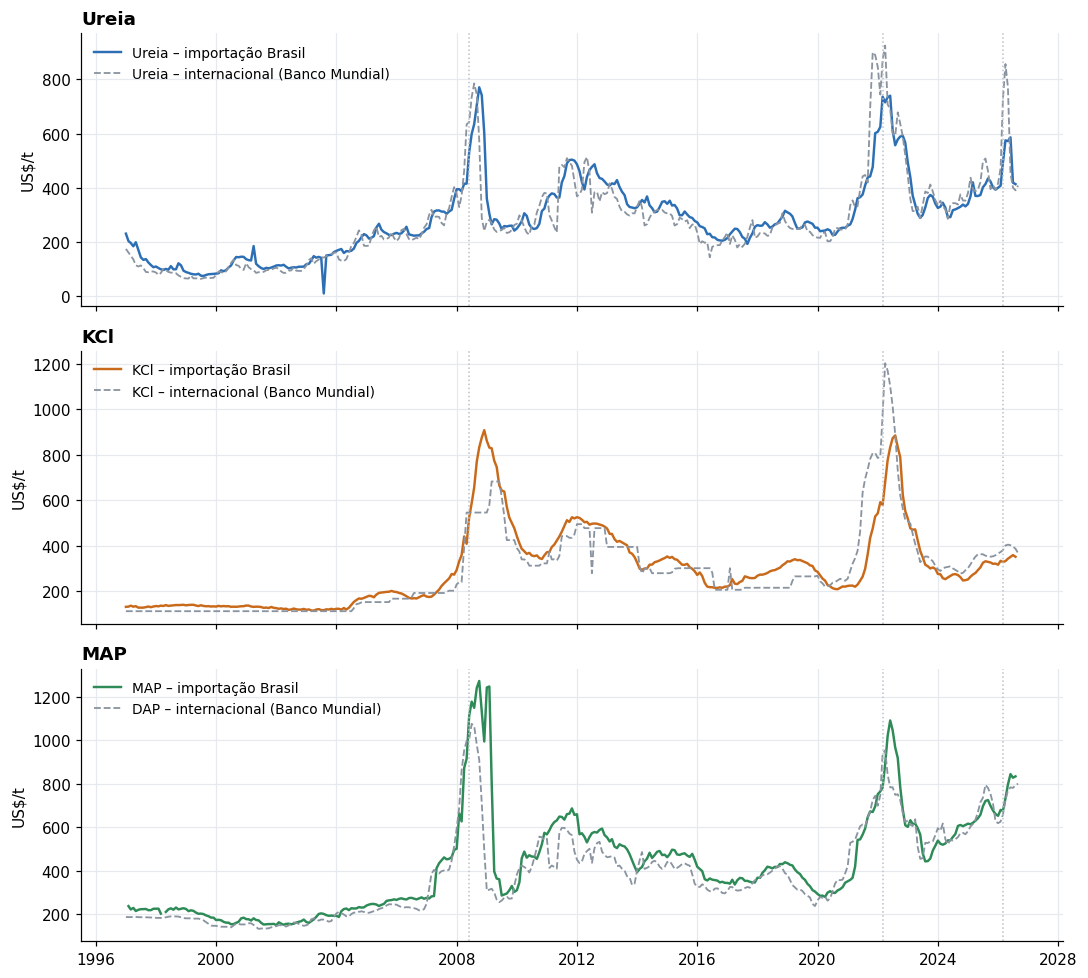

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, p, cor in zip(axes, ["Ureia", "KCl", "MAP"], [AZUL, LARANJA, VERDE]):
    ax.plot(br.index.to_timestamp(), br[p], color=cor, lw=1.6, label=f"{p} – importação Brasil")
    ax.plot(intl.loc["1997-01":].index.to_timestamp(), intl.loc["1997-01":, p], color=CINZA, lw=1.2, ls="--",
            label=f"{'DAP' if p == 'MAP' else p} – internacional (Banco Mundial)")
    for d, t in [("2008-06", "2008"), ("2022-03", "Guerra"), ("2026-03", "Ormuz")]:
        ax.axvline(pd.Period(d, "M").to_timestamp(), color="#B9C1CA", ls=":", lw=1)
    ax.set_ylabel("US$/t"); ax.legend(loc="upper left", frameon=False, fontsize=9); ax.set_title(p, loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "01_precos_por_fertilizante.png", bbox_inches="tight"); plt.show()

## 2. Choques por fertilizante

In [4]:
def media(p, a, b): return br.loc[a:b, p].mean()
linhas = []
for p in ["Ureia", "KCl", "MAP"]:
    jan26 = br.loc["2026-01", p]; pico26 = br.loc["2026-01":"2026-08", p]
    linhas.append({"Produto": p, "Média 2019": media(p, "2019-01", "2019-12"), "Média 2022": media(p, "2022-01", "2022-12"),
                   "Pico 2022": br.loc["2021-01":"2023-12", p].max(), "Mês do pico 2022": str(br.loc["2021-01":"2023-12", p].idxmax()),
                   "Média 2024–25": media(p, "2024-01", "2025-12"),
                   "Patamar 2024–25 vs 2019 (%)": 100 * (media(p, "2024-01", "2025-12") / media(p, "2019-01", "2019-12") - 1),
                   "Choque 2026: jan→pico (%)": 100 * (pico26.max() / jan26 - 1), "Mês do pico 2026": str(pico26.idxmax())})
choques = pd.DataFrame(linhas).set_index("Produto").round(1)
choques.to_csv(TAB / "01_choques_por_fertilizante.csv"); choques

,Média 2019,Média 2022,Pico 2022,Mês do pico 2022,Média 2024–25,Patamar 2024–25 vs 2019 (%),Choque 2026: jan→pico (%),Mês do pico 2026
Produto,,,,,,,,
Ureia,271.7,637.4,739.7,2022-06,357.1,31.4,46.6,2026-06
KCl,326.3,713.3,885.0,2022-08,283.0,-13.3,13.4,2026-07
MAP,373.8,859.3,1091.4,2022-06,613.0,64.0,29.4,2026-06


## 3. Quebras estruturais

O log do preço tem raiz unitária (seção 6), então quebras na média do nível não são bem definidas. Testamos dois tipos:

- **Regimes de volatilidade:** mudanças na média e na variância da variação log mensal, por programação dinâmica (segmento mínimo de 24 meses; número de quebras por BIC).
- **Mudança na dinâmica (Chow):** modelo AR(1) no log, com intercepto e coeficiente diferentes após datas conhecidas.

In [5]:
def regimes(y, max_k=8, min_size=24):
    d = np.log(y.interpolate()).diff().dropna(); x = d.values.reshape(-1, 1); n = len(x)
    algo = rpt.Dynp(model="normal", min_size=min_size, jump=1).fit(x)
    melhor, bic_min = [], np.inf
    for k in range(0, max_k + 1):
        bk = [] if k == 0 else algo.predict(n_bkps=k)[:-1]
        ll = sum(len(sg) * np.log(sg.var() + 1e-12) for sg in np.split(x.ravel(), bk))
        bic = ll + (3 * k + 2) * np.log(n)
        if bic < bic_min: bic_min, melhor = bic, bk
    segs = np.split(d, melhor)
    return pd.DataFrame({"início": [str(sg.index[0]) for sg in segs], "fim": [str(sg.index[-1]) for sg in segs],
                         "volatilidade mensal (%)": [round(sg.std() * 100, 1) for sg in segs]})

def chow(y, data):
    y = np.log(y.interpolate().dropna()); d = pd.DataFrame({"y": y.values}, index=y.index)
    d["ylag"] = d["y"].shift(1); d = d.dropna(); d["pos"] = (d.index >= pd.Period(data, "M")).astype(int)
    return smf.ols("y ~ ylag * pos", d).fit().f_test("pos = 0, ylag:pos = 0").pvalue

reg = pd.concat({p: regimes(br[p]) for p in ["Ureia", "KCl", "MAP"]}); reg.to_csv(TAB / "01_regimes_volatilidade.csv")
qb = pd.DataFrame({p: {f"Chow {d} (p)": round(chow(br[p], d), 3) for d in ["2008-07", "2021-06", "2022-03", "2026-03"]}
                   for p in ["Ureia", "KCl", "MAP"]}).T
qb.to_csv(TAB / "01_quebras_chow.csv")
display(reg); qb

início      fim  volatilidade mensal (%)
Ureia 0  1997-02  2001-03                      8.0
      1  2001-04  2003-09                     74.2
      2  2003-10  2008-05                      5.0
      3  2008-06  2011-09                     12.3
      4  2011-10  2021-02                      4.5
      5  2021-03  2026-08                      9.2
KCl   0  1997-02  2004-03                      2.0
      1  2004-04  2008-01                      3.8
      2  2008-02  2010-03                     10.0
      3  2010-04  2021-05                      3.4
      4  2021-06  2023-08                     10.7
      5  2023-09  2026-08                      3.3
MAP   0  1997-03  2004-07                      3.9
      1  2004-08  2007-04                      1.8
      2  2007-05  2010-03                     19.7
      3  2010-04  2021-03                      3.8
      4  2021-04  2023-08                      9.5
      5  2023-09  2026-08                      3.2

,Chow 2008-07 (p),Chow 2021-06 (p),Chow 2022-03 (p),Chow 2026-03 (p)
Ureia,0.0,0.161,0.451,0.508
KCl,0.0,0.153,0.083,0.890
MAP,0.0,0.505,0.838,0.406


## 4. Sazonalidade

**Volume:** participação de cada mês no volume anual (2015–2025). **Preço:** teste F de dummies mensais na variação log (2000–2025) e força sazonal da decomposição STL (Wang, Smith e Hyndman, 2006).

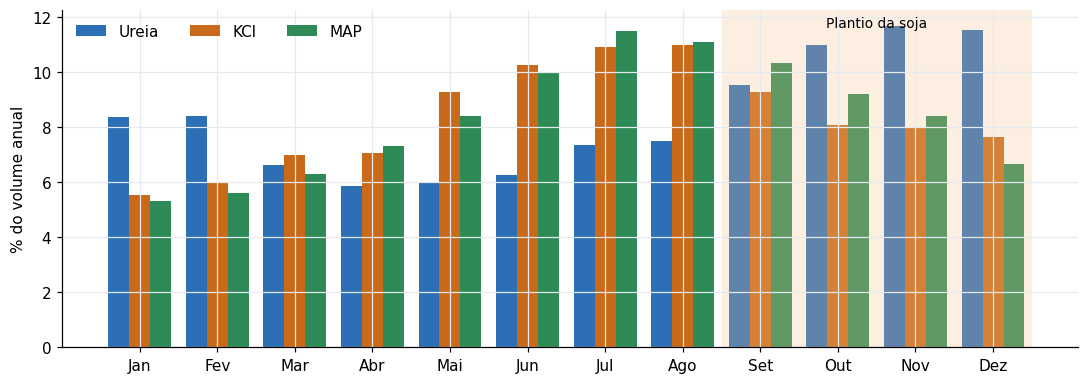

,p-valor F (dummies),Força sazonal STL (0–1),Janela de compra,% do volume na janela
Produto,,,,
Ureia,0.404,0,Set–Dez,43.7
KCl,0.696,0,Mai–Set,50.8
MAP,0.374,0,Mai–Set,51.3


In [6]:
v = vol.loc["2015-01":"2025-12"]
part = v.groupby(v.index.month).sum(); part = part / part.sum() * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
w = 0.27; meses = np.arange(1, 13)
for i, (p, cor) in enumerate(zip(["Ureia", "KCl", "MAP"], [AZUL, LARANJA, VERDE])):
    ax.bar(meses + (i - 1) * w, part[p], width=w, color=cor, label=p)
ax.set_xticks(meses, ["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"])
ax.set_ylabel("% do volume anual"); ax.legend(frameon=False, ncol=3)
ax.axvspan(8.5, 12.5, color="#F6C28B", alpha=0.25, lw=0); ax.text(10.5, ax.get_ylim()[1]*0.95, "Plantio da soja", ha="center", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "01_sazonalidade_volume.png", bbox_inches="tight"); plt.show()

linhas = []
for p in ["Ureia", "KCl", "MAP"]:
    y = br[p].loc["2000-01":"2025-12"].interpolate()
    dl = np.log(y).diff().dropna(); d = pd.DataFrame({"dl": dl, "m": dl.index.month})
    pv = smf.ols("dl ~ C(m)", d).fit(cov_type="HC1").f_pvalue
    st = STL(np.log(y).values, period=12, robust=True).fit()
    forca = max(0, 1 - np.var(st.resid) / np.var(st.resid + st.seasonal))
    jan_compra = [5, 6, 7, 8, 9] if p != "Ureia" else [9, 10, 11, 12]
    linhas.append({"Produto": p, "p-valor F (dummies)": round(pv, 3), "Força sazonal STL (0–1)": round(forca, 2),
                   "Janela de compra": "Mai–Set" if p != "Ureia" else "Set–Dez",
                   "% do volume na janela": round(part.loc[jan_compra, p].sum(), 1)})
saz = pd.DataFrame(linhas).set_index("Produto"); saz.to_csv(TAB / "01_sazonalidade.csv"); saz

## 5. Defasagem internacional → Brasil

Correlação entre a variação mensal do preço brasileiro em *t* e a do internacional em *t − k*.

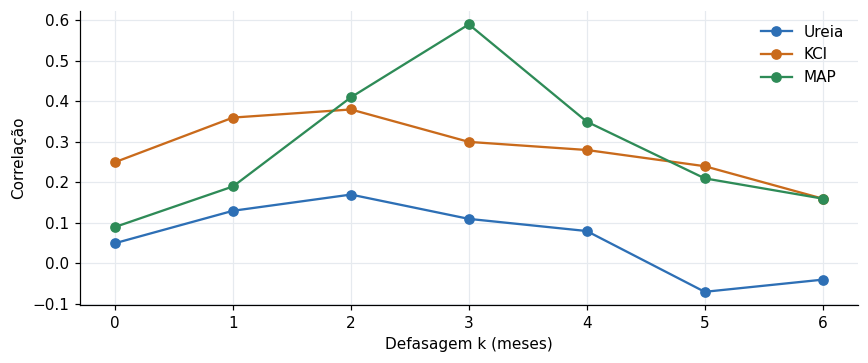

,k=0,k=1,k=2,k=3,k=4,k=5,k=6
Ureia,0.05,0.13,0.17,0.11,0.08,-0.07,-0.04
KCl,0.25,0.36,0.38,0.30,0.28,0.24,0.16
MAP,0.09,0.19,0.41,0.59,0.35,0.21,0.16


In [7]:
lag = {}
for p in ["Ureia", "KCl", "MAP"]:
    b = np.log(br[p]).diff(); i_ = np.log(intl[p]).diff()
    lag[p] = {f"k={k}": b.corr(i_.shift(k)) for k in range(0, 7)}
lag = pd.DataFrame(lag).T.round(2); lag.to_csv(TAB / "01_defasagem_internacional.csv")
fig, ax = plt.subplots(figsize=(8, 3.4))
for p, cor in zip(lag.index, [AZUL, LARANJA, VERDE]):
    ax.plot(range(7), lag.loc[p].values, marker="o", color=cor, label=p)
ax.set_xlabel("Defasagem k (meses)"); ax.set_ylabel("Correlação"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "01_defasagem.png", bbox_inches="tight"); plt.show(); lag

## 6. Estacionariedade (log do preço)

ADF (H0: raiz unitária) e KPSS (H0: estacionária), em nível e em primeira diferença.

In [8]:
linhas = []
for p in ["Ureia", "KCl", "MAP"]:
    y = np.log(br[p].interpolate().dropna())
    for nome, serie in [("nível", y), ("1ª diferença", y.diff().dropna())]:
        linhas.append({"Produto": p, "Série": nome, "ADF p": round(adfuller(serie, autolag="AIC")[1], 3),
                       "KPSS p": round(kpss(serie, regression="c", nlags="auto")[1], 3)})
est = pd.DataFrame(linhas).set_index(["Produto", "Série"]); est.to_csv(TAB / "01_estacionariedade.csv"); est

/sessions/rcw-01fk3rkeelj2n1ybmfteftyl/tmp/ipykernel_10/2609636770.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  "KPSS p": round(kpss(serie, regression="c", nlags="auto")[1], 3)})
/sessions/rcw-01fk3rkeelj2n1ybmfteftyl/tmp/ipykernel_10/2609636770.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  "KPSS p": round(kpss(serie, regression="c", nlags="auto")[1], 3)})
/sessions/rcw-01fk3rkeelj2n1ybmfteftyl/tmp/ipykernel_10/2609636770.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  "KPSS p": round(kpss(serie, regression="c", nlags="auto")[1], 3)})
/sessions/rcw-01fk3rkeelj2n1ybmfteftyl/tmp/ipykernel_10/2609636770.py:6: Int

ADF p  KPSS p
Produto Série                      
Ureia   nível         0.282    0.01
        1ª diferença  0.000    0.10
KCl     nível         0.292    0.01
        1ª diferença  0.000    0.10
MAP     nível         0.405    0.01
        1ª diferença  0.000    0.10

## 7. Implicações para a modelagem (resultado de 10/10/2026)

- **Choques:** em 2024–25 o KCl voltou abaixo do patamar de 2019 (−13%), mas a ureia ficou +31% e o MAP +64%. Em 2026 (Ormuz),
  ureia +47% e MAP +29% de janeiro ao pico; KCl só +13%. **Cada fertilizante precisa do seu modelo.**
- **Quebras:** o choque de 2022 aparece como **regime de alta volatilidade de 2021 a set/2023** (KCl e MAP) e não como mudança
  na dinâmica AR(1) — o teste de Chow só rejeita em 2008. Para a ureia, a alta volatilidade começa em 2021 e segue até 2026.
  → usar dummies de regime/variância (ou modelos com volatilidade variável) e avaliar o erro por regime.
- **Sazonalidade:** o **preço não é sazonal** no nível do produto (teste F e STL); o **volume é** (44–51% do ano na janela de compra).
  → ARIMA em vez de SARIMA como baseline; o calendário entra na **avaliação ponderada pelo volume** da janela de compra.
- **Defasagem:** o preço brasileiro segue o internacional com 1–3 meses (MAP: correlação 0,59 com 3 meses) → bom sinal para h = 1 a 3.
- **Estacionariedade:** log do preço é I(1) → modelar a **primeira diferença do log**.